In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [19]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])


In [ ]:
df = df.drop(columns=['Cabin'])

In [21]:
print(df['Age'].isna().sum())
print(df['Embarked'].isna().sum())

0
0


In [22]:
df = pd.read_csv("train.csv")

X = df.drop(columns=["Survived"])
y = df["Survived"]

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
print("Train set size:", X_train.shape)
print("Validation set size:", X_val.shape)


Train set size: (712, 11)
Validation set size: (179, 11)


In [30]:
features = ["Pclass", "Age", "Sex"]

X_train_selected = X_train[features]
X_val_selected = X_val[features]

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

preprocessor = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("class", "passthrough", ["Pclass"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train_selected, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('class', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [33]:
y_pred = model.predict(X_val_selected)

accuracy = accuracy_score(y_val, y_pred)

print(f"Accuracy : {accuracy:.2%}")

Accuracy : 79.33%


In [34]:
y_val.value_counts(normalize=True)

Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64

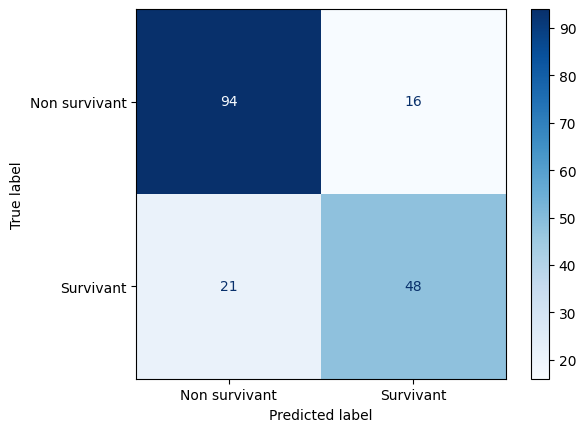

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["Non survivant", "Survivant"],
    cmap="Blues"
)

plt.show()

In [36]:
y_proba = model.predict_proba(X_val_selected)[:, 1]

y_pred_20 = (y_proba >= 0.20).astype(int)

In [37]:
from sklearn.metrics import precision_score, recall_score

print("Precision :", precision_score(y_val, y_pred_20))
print("Recall :", recall_score(y_val, y_pred_20))

Precision : 0.5686274509803921
Recall : 0.8405797101449275


In [38]:
from sklearn.metrics import f1_score

print("F1 seuil 50 % :", f1_score(y_val, y_pred))
print("F1 seuil 20 % :", f1_score(y_val, y_pred_20))

F1 seuil 50 % : 0.7218045112781954
F1 seuil 20 % : 0.6783625730994152


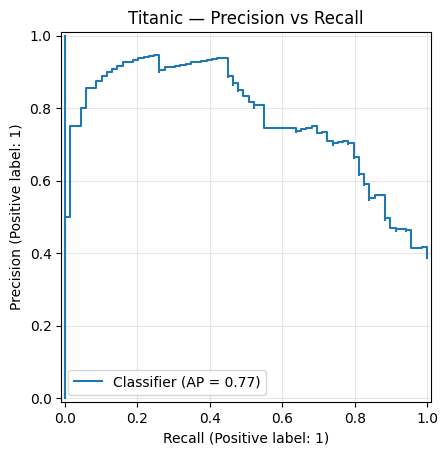

In [39]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

PrecisionRecallDisplay.from_predictions(
    y_val,
    y_proba
)

plt.title("Titanic — Precision vs Recall")
plt.grid(alpha=0.3)
plt.show()


In [40]:
features_v2 = ["Pclass", "Age", "Sex", "SibSp"]

X_train_v2 = X_train[features_v2]
X_val_v2 = X_val[features_v2]

In [47]:
preprocessor_v2 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "SibSp"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v2 = Pipeline([
    ("preprocessing", preprocessor_v2),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v2.fit(X_train_v2, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [50]:
y_pred_v2 = model_v2.predict(X_val_v2)

accuracy_v2 = accuracy_score(y_val, y_pred_v2)
f1_v2 = f1_score(y_val, y_pred_v2)

print(f"Accuracy V2 : {accuracy_v2:.2%}")
print(f"F1-score V2 : {f1_v2:.4f}")

Accuracy V2 : 79.33%
F1-score V2 : 0.7176


In [53]:
features_v3 = ["Pclass", "Age", "Sex", "Parch"]

X_train_v3 = X_train[features_v3]
X_val_v3 = X_val[features_v3]

In [54]:
preprocessor_v3 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "Parch"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v3 = Pipeline([
    ("preprocessing", preprocessor_v3),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v3.fit(X_train_v3, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [55]:
y_pred_v3 = model_v3.predict(X_val_v3)

accuracy_v3 = accuracy_score(y_val, y_pred_v3)
f1_v3 = f1_score(y_val, y_pred_v3)

print(f"Accuracy V3 : {accuracy_v3:.2%}")
print(f"F1-score V3 : {f1_v3:.4f}")

Accuracy V3 : 78.21%
F1-score V3 : 0.7153


In [56]:
features_v4 = ["Pclass", "Age", "Sex", "Fare"]

X_train_v4 = X_train[features_v4]
X_val_v4 = X_val[features_v4]

In [57]:
preprocessor_v4 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "Fare"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v4 = Pipeline([
    ("preprocessing", preprocessor_v4),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v4.fit(X_train_v4, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [58]:
y_pred_v4 = model_v4.predict(X_val_v4)

accuracy_v4 = accuracy_score(y_val, y_pred_v4)
f1_v4 = f1_score(y_val, y_pred_v4)

print(f"Accuracy V4 : {accuracy_v4:.2%}")
print(f"F1-score V4 : {f1_v4:.4f}")

Accuracy V4 : 79.33%
F1-score V4 : 0.7218


In [60]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring="f1"
)
scores_v2 = cross_val_score(
    model_v2,
    X_train_v2,
    y_train,
    cv=cv,
    scoring="f1"
)

scores_v3 = cross_val_score(
    model_v3,
    X_train_v3,
    y_train,
    cv=cv,
    scoring="f1"
)

scores_v4 = cross_val_score(
    model_v4,
    X_train_v4,
    y_train,
    cv=cv,
    scoring="f1"
)


print("Scores :", scores)
print("F1 moyen :", scores.mean())
print("Écart-type :", scores.std())

print("Scores V2 :", scores_v2)
print("F1 moyen V2 :", scores_v2.mean())
print("Écart-type V2 :", scores_v2.std())

print("Scores V3 :", scores_v3)
print("F1 moyen V3 :", scores_v3.mean())
print("Écart-type V3 :", scores_v3.std())

print("Scores V4 :", scores_v4)
print("F1 moyen V4 :", scores_v4.mean())
print("Écart-type V4 :", scores_v4.std())


Scores : [0.73214286 0.66       0.76190476 0.71304348 0.75247525]
F1 moyen : 0.7239132689666482
Écart-type : 0.03613841329212142
Scores V2 : [0.71428571 0.68627451 0.75925926 0.69090909 0.74      ]
F1 moyen V2 : 0.7181457148515971
Écart-type V2 : 0.028072906199585426
Scores V3 : [0.71929825 0.67346939 0.72380952 0.7008547  0.75247525]
F1 moyen V3 : 0.7139814211116228
Écart-type V3 : 0.026154045686040392
Scores V4 : [0.73214286 0.66       0.76190476 0.71304348 0.74      ]
F1 moyen V4 : 0.7214182194616976
Écart-type V4 : 0.03447258189456054


In [81]:
X_train_v5 = X_train.copy()
X_val_v5 = X_val.copy()

X_train_v5["FamilySize"] = (
    X_train_v5["SibSp"] + X_train_v5["Parch"] + 1
)

X_val_v5["FamilySize"] = (
    X_val_v5["SibSp"] + X_val_v5["Parch"] + 1
)

In [82]:
features_v5 = ["Pclass", "Age", "Sex", "FamilySize"]

X_train_v5 = X_train_v5[features_v5]
X_val_v5 = X_val_v5[features_v5]

In [83]:
preprocessor_v5 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "FamilySize"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v5 = Pipeline([
    ("preprocessing", preprocessor_v5),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v5.fit(X_train_v5, y_train)


,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [85]:
scores_v5 = cross_val_score(
    model_v5,
    X_train_v5,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores V5 :", scores_v5)
print("F1 moyen V5 :", scores_v5.mean())
print("Écart-type V5 :", scores_v5.std())

Scores V5 : [0.71428571 0.6728972  0.75471698 0.69026549 0.74      ]
F1 moyen V5 : 0.7144330756810271
Écart-type V5 : 0.03028459677114981


In [86]:
print("Features :", X_train_v5.columns.tolist())

print(
    "FamilySize correcte :",
    (
        X_train_v5["FamilySize"]
        == X_train["SibSp"] + X_train["Parch"] + 1
    ).all()
)

print("Préprocesseur :", model_v5.named_steps["preprocessing"])

Features : ['Pclass', 'Age', 'Sex', 'FamilySize']
FamilySize correcte : True
Préprocesseur : ColumnTransformer(transformers=[('age', SimpleImputer(strategy='median'),
                                 ['Age']),
                                ('numeric', 'passthrough',
                                 ['Pclass', 'FamilySize']),
                                ('sex', OneHotEncoder(handle_unknown='ignore'),
                                 ['Sex'])])


In [87]:
features_v6 = ["Pclass", "Age", "Sex", "SibSp", "Parch"]

X_train_v6 = X_train[features_v6]
X_val_v6 = X_val[features_v6]

In [88]:
preprocessor_v6 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "SibSp", "Parch"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v6 = Pipeline([
    ("preprocessing", preprocessor_v6),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v6.fit(X_train_v6, y_train)


,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [91]:
scores_v6 = cross_val_score(
    model_v6,
    X_train_v6,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores V6 :", scores_v6)
print("F1 moyen V6 :", scores_v6.mean())
print("Écart-type V6 :", scores_v6.std())


Scores V6 : [0.71428571 0.6728972  0.75471698 0.67857143 0.74      ]
F1 moyen V6 : 0.7120942640501802
Écart-type V6 : 0.03243584186122116


In [92]:
X_train_v7 = X_train.copy()
X_val_v7 = X_val.copy()

X_train_v7["IsAlone"] = (
    (X_train_v7["SibSp"] + X_train_v7["Parch"]) == 0
).astype(int)

X_val_v7["IsAlone"] = (
    (X_val_v7["SibSp"] + X_val_v7["Parch"]) == 0
).astype(int)

In [93]:
features_v7 = ["Pclass", "Age", "Sex","IsAlone"]

X_train_v7 = X_train_v7[features_v7]
X_val_v7 = X_val_v7[features_v7]

In [75]:
preprocessor_v7 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "IsAlone"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v7 = Pipeline([
    ("preprocessing", preprocessor_v7),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v7.fit(X_train_v7, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [94]:
scores_v7 = cross_val_score(
    model_v7,
    X_train_v7,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores V7 :", scores_v7)
print("F1 moyen V7 :", scores_v7.mean())
print("Écart-type V7 :", scores_v7.std())


Scores V7 : [0.71929825 0.67326733 0.74545455 0.70689655 0.74509804]
F1 moyen V7 : 0.7180029417482157
Écart-type V7 : 0.026885088116320812


In [96]:

X_train_v8 = X_train.copy()
X_val_v8 = X_val.copy()

X_train_v8["FamilySize"] = (
    X_train_v8["SibSp"] + X_train_v8["Parch"] + 1
)

X_val_v8["FamilySize"] = (
    X_val_v8["SibSp"] + X_val_v8["Parch"] + 1
)


X_train_v8["IsAlone"] = (
    X_train_v8["FamilySize"] == 1
).astype(int)

X_val_v8["IsAlone"] = (
    X_val_v8["FamilySize"] == 1
).astype(int)


features_v8 = [
    "Pclass","Age","Sex","FamilySize","IsAlone","Fare"]

X_train_v8 = X_train_v8[features_v8]
X_val_v8 = X_val_v8[features_v8]


preprocessor_v8 = ColumnTransformer([
    ("impute", SimpleImputer(strategy="median"), ["Age", "Fare"]),
    ("numeric", "passthrough", ["Pclass", "FamilySize", "IsAlone"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])


model_v8 = Pipeline([
    ("preprocessing", preprocessor_v8),
    ("classifier", LogisticRegression(max_iter=1000))
])


scores_v8 = cross_val_score(
    model_v8,
    X_train_v8,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores v8 :", scores_v8)
print("F1 moyen v8 :", scores_v8.mean())
print("Écart-type v8 :", scores_v8.std())



Scores v8 : [0.72727273 0.68686869 0.76470588 0.70175439 0.73786408]
F1 moyen v8 : 0.7236931520258342
Écart-type v8 : 0.02732406716368451


In [97]:
for name, pipeline, data in [
    ("V1", model, X_train_selected),
    ("V8", model_v8, X_train_v8)
]:
    scores = cross_val_score(
        pipeline,
        data,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    print(f"{name} : {scores.mean():.4f} ± {scores.std():.4f}")

V1 : 0.7936 ± 0.0265
V8 : 0.7950 ± 0.0239


In [100]:

train_full = pd.read_csv("train.csv")
test_kaggle = pd.read_csv("test.csv")


def create_features(data):
    data = data.copy()

    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

    return data[features_v8]

X_full = create_features(train_full)
y_full = train_full["Survived"]

X_test = create_features(test_kaggle)


model_v8.fit(X_full, y_full)


predictions = model_v8.predict(X_test)


submission = pd.DataFrame({
    "PassengerId": test_kaggle["PassengerId"],
    "Survived": predictions
})

submission.to_csv("submission_v8.csv", index=False)

print(submission.head())
print("Dimensions :", submission.shape)


   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1
Dimensions : (418, 2)


In [99]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

model_v8.fit(X_train_v8, y_train)

y_pred_v8 = model_v8.predict(X_val_v8)

print("Accuracy :", accuracy_score(y_val, y_pred_v8))
print("F1-score :", f1_score(y_val, y_pred_v8))
print("\nRapport de classification :\n", classification_report(y_val, y_pred_v8))
print("\nMatrice de confusion :\n", confusion_matrix(y_val, y_pred_v8))

Accuracy : 0.8100558659217877
F1-score : 0.7424242424242424

Rapport de classification :
               precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.71      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179


Matrice de confusion :
 [[96 14]
 [20 49]]


In [104]:
from sklearn.ensemble import RandomForestClassifier


model_rf = Pipeline([
    ("preprocessing", preprocessor_v8),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

scores_acc_rf = cross_val_score(
    model_rf,
    X_train_v8,
    y_train,
    cv=cv,
    scoring="accuracy"
)

scores_f1_rf = cross_val_score(
    model_rf,
    X_train_v8,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Accuracy RandomForest:", scores_acc_rf)
print("Accuracy moyenne :", scores_acc_rf.mean())
print("Écart-type :", scores_acc_rf.std())
print()
print("F1 RandomForest :", scores_f1_rf)
print("F1 moyen :", scores_f1_rf.mean())




Accuracy RandomForest: [0.83916084 0.79020979 0.83802817 0.80985915 0.83098592]
Accuracy moyenne : 0.8216487737614498
Écart-type : 0.018918477941267633

F1 RandomForest : [0.78899083 0.70588235 0.75789474 0.73267327 0.76      ]
F1 moyen : 0.7490882365596174


In [105]:
# Vérification d'un potentiel sur-apprentissage avec le RandomForestClassifier

model_rf.fit(X_train_v8, y_train)

print("Accuracy train :", model_rf.score(X_train_v8, y_train))
print("Accuracy validation :", model_rf.score(X_val_v8, y_val))

Accuracy train : 0.8455056179775281
Accuracy validation : 0.8044692737430168


In [107]:
train_full = pd.read_csv("train.csv")
test_kaggle = pd.read_csv("test.csv")

X_full = create_features(train_full)
y_full = train_full["Survived"]
X_test = create_features(test_kaggle)

model_rf.fit(X_full, y_full)

predictions_rf = model_rf.predict(X_test)

submission_rf = pd.DataFrame({
    "PassengerId": test_kaggle["PassengerId"],
    "Survived": predictions_rf
})

submission_rf.to_csv("submission_rf.csv", index=False)

print(submission_rf.shape)
print(submission_rf.head())

(418, 2)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1


In [108]:
v8 = pd.read_csv("submission_v8.csv")
v9 = pd.read_csv("submission_rf.csv")

assert v8["PassengerId"].equals(v9["PassengerId"])

differences = v8["Survived"] != v9["Survived"]

print("Prédictions différentes :", differences.sum())
print("Prédictions identiques :", (~differences).sum())

print(pd.crosstab(
    v8["Survived"],
    v9["Survived"],
    rownames=["Logistic Regression"],
    colnames=["Random Forest"]
))

Prédictions différentes : 30
Prédictions identiques : 388
Random Forest          0    1
Logistic Regression          
0                    254   10
1                     20  134


In [110]:
model_v8.fit(X_train_v8, y_train)
model_rf.fit(X_train_v8, y_train)

pred_v8 = model_v8.predict(X_val_v8)
pred_rf = model_rf.predict(X_val_v8)

print("Désaccords :", (pred_v8 != pred_rf).sum())

print("V8 seule correcte :", (
    (pred_v8 == y_val) & (pred_rf != y_val)
).sum())

print("RF seule correcte :", (
    (pred_rf == y_val) & (pred_v8 != y_val)
).sum())

print("Les deux incorrectes :", (
    (pred_v8 != y_val) & (pred_rf != y_val)
).sum())

Désaccords : 11
V8 seule correcte : 6
RF seule correcte : 5
Les deux incorrectes : 29
